# The testing notebook

Idea of this notebook is to better understand the dataset and how to use it. There aren't any final solutions here.

Useful imports

In [1]:
#%pip install fastf1
#%pip install python-dotenv

import os
import fastf1
from dotenv import load_dotenv

## Day 0 - Testing for the size

In [2]:
#Getting account sign in for data
load_dotenv()
os.environ['F1_USERNAME'] = os.getenv('F1_USERNAME')
os.environ['F1_PASSWORD'] = os.getenv('F1_PASSWORD')

#Cashe configuration
fastf1.Cache.enable_cache('data/cache')

#We take our planed qualifying
session = fastf1.get_session(2026, 'Singapore', 'Q')
session.load()

#Laps check
laps = session.laps
print("Laps shape:", laps.shape)
display(laps.head())

/home/zero/miniconda3/envs/IDS/lib/python3.13/site-packages/fastf1/req.py:251: FutureWarning: `.enable_cache` is deprecated and will be removed in a future version. Use `.configure` instead.
  warnings.warn("`.enable_cache` is deprecated and will be removed in a "
core           INFO 	Loading data for Singapore Grand Prix - Qualifying [v3.9.0]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INF

Laps shape: (363, 31)


,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,...,FreshTyre,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate
0,0 days 00:19:18.397000,VER,3,NaT,1.0,1.0,0 days 00:17:21.662000,NaT,NaT,0 days 00:00:46.603000,...,False,Red Bull Racing,0 days 00:17:21.662000,2026-10-10 13:34:13.409,12,NaN,False,,False,False
1,0 days 00:20:51.638000,VER,3,0 days 00:01:33.241000,2.0,1.0,NaT,NaT,0 days 00:00:27.674000,0 days 00:00:39.190000,...,False,Red Bull Racing,0 days 00:19:18.397000,2026-10-10 13:36:10.144,21,NaN,False,,False,True
2,0 days 00:23:10.836000,VER,3,0 days 00:02:19.198000,3.0,1.0,NaT,0 days 00:22:33.185000,0 days 00:00:31.359000,0 days 00:00:41.700000,...,False,Red Bull Racing,0 days 00:20:51.638000,2026-10-10 13:37:43.385,1,NaN,False,,False,False
3,0 days 00:41:24.005000,VER,3,NaT,4.0,2.0,0 days 00:39:16.230000,NaT,NaT,0 days 00:00:47.833000,...,True,Red Bull Racing,0 days 00:23:10.836000,2026-10-10 13:40:02.583,1,NaN,False,,False,False
4,0 days 00:42:56.297000,VER,3,0 days 00:01:32.292000,5.0,2.0,NaT,NaT,0 days 00:00:27.363000,0 days 00:00:38.840000,...,True,Red Bull Racing,0 days 00:41:24.005000,2026-10-10 13:58:15.752,1,NaN,False,,False,True


In [3]:
#Kurvide info saamine
circuit_info = session.get_circuit_info()
corners = circuit_info.corners
display(corners)

,X,Y,Number,Letter,Angle,Distance
0,431.132652,3476.576339,1,,40.098991,392.951373
1,-195.214034,3722.206835,2,,-116.338121,464.579726
2,-779.754260,4085.899970,3,,108.318126,531.883815
3,-1000.248495,2762.565807,4,,-159.825842,677.706777
4,-704.275136,290.498744,5,,-56.175072,954.987736
5,-4914.428676,446.078774,6,,-99.405340,1372.227678
6,-8210.484032,2141.918937,7,,84.288029,1738.793166
7,-9608.455015,545.234452,8,,-137.554884,1970.263056
8,-11035.325463,1643.483060,9,,-77.178353,2158.269656
9,-13197.999977,-1883.988437,10,,-182.928561,2592.258909


## Day 10 - Testing for the size(8.11)

/home/zero/miniconda3/envs/IDS/lib/python3.13/site-packages/fastf1/plotting/_plotting.py:56: FutureWarning: The `misc_mpl_mods` argument was dropped from `.setup_mpl()` in version 3.6.0 and has no effect anymore. It will be removed in a future version of FastF1.
  warnings.warn(
/home/zero/miniconda3/envs/IDS/lib/python3.13/site-packages/fastf1/core.py:3245: FutureWarning: pick_driver is deprecated and will be removed in a future release. Use pick_drivers instead.
  warnings.warn(("pick_driver is deprecated and will be removed"


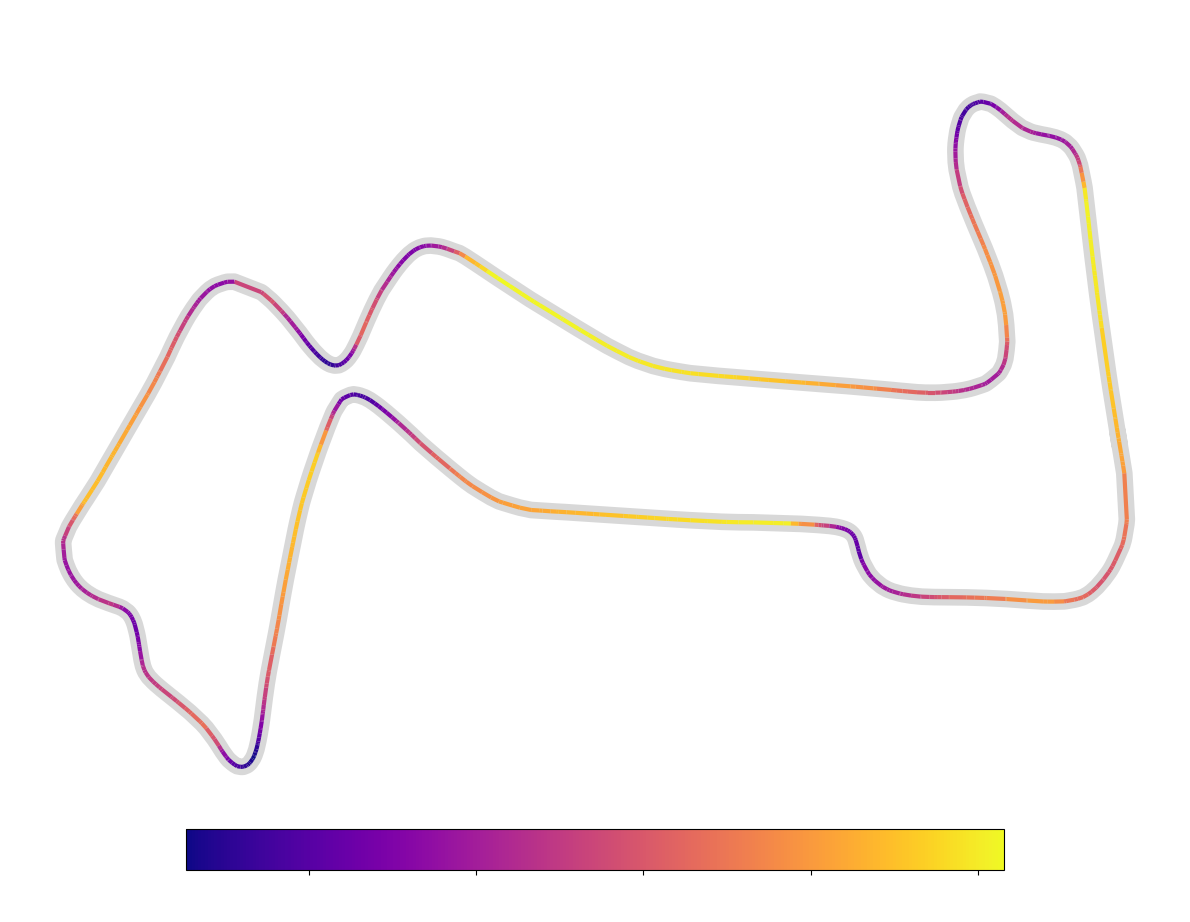

In [8]:
#AI showing how the data can even show map data. I won't be able to explain the code yet, but its one way to show the data. 
#Code has been made by gemini, IF I am going to use it I must understand it. 

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
import fastf1.plotting

fastf1.plotting.setup_mpl(misc_mpl_mods=False)

# 1. Võtame Leclerc'i kiireima kehtiva ringi telemeetria
lec_lap = laps.pick_driver('LEC').pick_quicklaps().pick_fastest()
tel = lec_lap.get_telemetry()

# 2. Võtame koordinaadid ja kiiruse
x = tel['X']
y = tel['Y']
speed = tel['Speed']

# 3. Joonistame graafiku
fig, ax = plt.subplots(figsize=(12, 10))

# A) Taustarada (laia halli joonena, et näha raja üldist asukohta)
ax.plot(x, y, color='gray', linewidth=12, alpha=0.3, label='Track Bounds (approx)')

# B) Leclerc'i täpne Racing Line kiiruse värvikoodiga
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

norm = plt.Normalize(speed.min(), speed.max())
lc = LineCollection(segments, cmap='plasma', norm=norm, linewidth=3, zorder=3)
lc.set_array(speed)
ax.add_collection(lc)

ax.autoscale()
ax.set_aspect('equal')
ax.axis('off')

# Lisame kiiruse skaala
cbar = fig.colorbar(lc, ax=ax, orientation='horizontal', pad=0.03, shrink=0.7)
cbar.set_label('Kiirus (km/h)', fontsize=10, fontweight='bold', color='white')
cbar.ax.tick_params(labelsize=9, labelcolor='white')

plt.title(
    f"Charles Leclerc — Racing Line & Position on Track\nLap Time: {lec_lap['LapTime'].total_seconds():.3f}s",
    color='white', fontsize=13, fontweight='bold', pad=15
)

# --- NIPP: SUURENDAMINE (ZOOM) TÄPSE KURVI JAOKS ---
# Kui soovid mõnda konkreetset laia kurvi lähedalt vaadata, eemalda järgmistelt ridadelt trellid (#) 
# ja reguleeri koordinaate (vaata X ja Y väärtusi telemeetriast):
# ax.set_xlim(-2000, 1000)
# ax.set_ylim(-4000, -1000)

plt.tight_layout()
plt.show()

/home/zero/miniconda3/envs/IDS/lib/python3.13/site-packages/fastf1/plotting/_plotting.py:56: FutureWarning: The `misc_mpl_mods` argument was dropped from `.setup_mpl()` in version 3.6.0 and has no effect anymore. It will be removed in a future version of FastF1.
  warnings.warn(


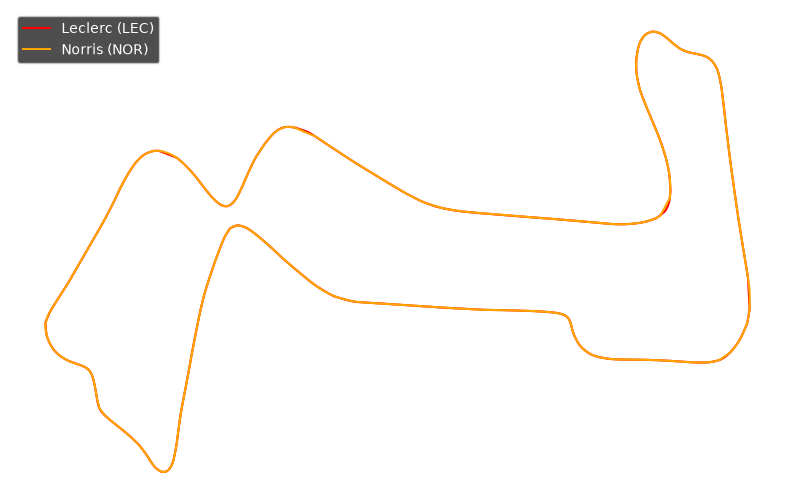

In [9]:
import matplotlib.pyplot as plt
import fastf1.plotting

fastf1.plotting.setup_mpl(misc_mpl_mods=False)

# Fixime ära ka hoiatuses teada antud vananenud funktsiooni (pick_driver -> laps.pick_drivers)
lec_lap = laps.pick_drivers('LEC').pick_quicklaps().pick_fastest()
nor_lap = laps.pick_drivers('NOR').pick_quicklaps().pick_fastest()

tel_lec = lec_lap.get_telemetry()
tel_nor = nor_lap.get_telemetry()

fig, ax = plt.subplots(figsize=(10, 8))

# Joonistame mõlemad trajektoorid peenikese joonena
ax.plot(tel_lec['X'], tel_lec['Y'], color='red', label='Leclerc (LEC)', linewidth=1.5)
ax.plot(tel_nor['X'], tel_nor['Y'], color='orange', label='Norris (NOR)', linewidth=1.5)

ax.set_aspect('equal')
ax.axis('off')
plt.legend(facecolor='#222222', labelcolor='white')

# --- SUUMA KOODIGA KURVI SISSE ---
# Näiteks suuname vaate ühele konkreetsele kurvile, kus erinevus välja tuleb:
# ax.set_xlim(tel_lec['X'].min() + 1000, tel_lec['X'].min() + 2500)
# ax.set_ylim(tel_lec['Y'].min() + 1000, tel_lec['Y'].min() + 2500)

plt.show()

Inconclusion comparing racing lines might be impossible and out of my skill set also, because that would mean I need to learn how to use maps with graphs. Also the GPS data isn't that accurate so there is no point to it.